Saved cleanly to target folder: E:\CAZ-Again\Figure1\Figs\DeltaP_Persistence_BlueWhiteRed.png


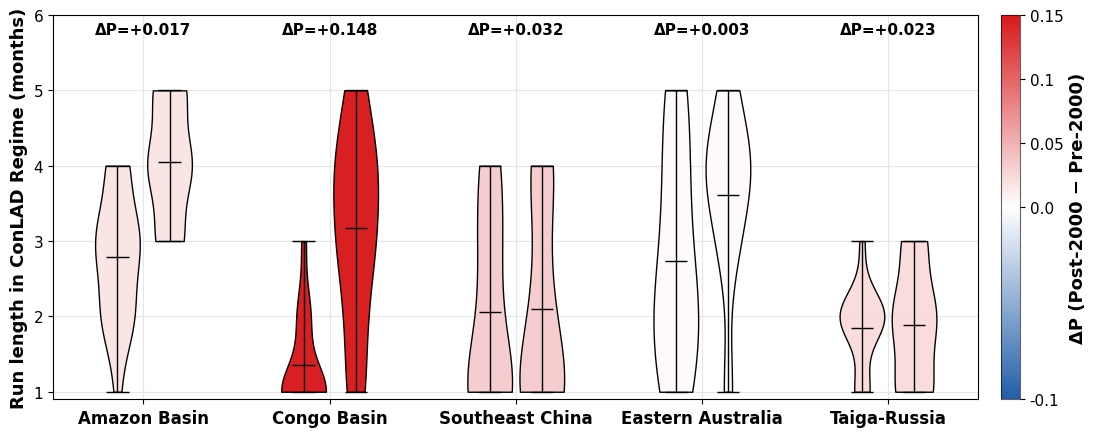

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from pathlib import Path
import scipy.io as sio
import matplotlib.patches as mpatches

# ==================== Global font settings ====================
mpl.rcParams['font.family']       = 'DejaVu Sans'
mpl.rcParams['mathtext.fontset']  = 'dejavusans'
mpl.rcParams['font.size']         = 14          # Increased base scale
mpl.rcParams['font.weight']       = 'normal'
mpl.rcParams['axes.labelweight']  = 'bold'
mpl.rcParams['axes.titleweight']  = 'bold'
mpl.rcParams['axes.labelsize']    = 14          # Axis labels base size
mpl.rcParams['xtick.labelsize']   = 12          # Tick labels base size
mpl.rcParams['ytick.labelsize']   = 12
mpl.rcParams['legend.fontsize']   = 12

# ==================== Paths ====================
BASE = Path("E:/CAZ-Again/Figure1")

# UPDATED: 1981-2018 SM/VPD file
mat_path = BASE / "Fareeha_data_SM_VPD_1981_2018.mat"

# FIX: Set output directory explicitly to the target folder
FIG_DIR = BASE / "Figs"

# ==================== Regions ====================
REGIONS = ["Amazon","Congo","China","QL","Taiga"]
REGION_PRETTY = {
    "Amazon":"Amazon Basin",
    "Congo":"Congo Basin",
    "China":"Southeast China",
    "QL":"Eastern Australia",
    "Taiga":"Taiga-Russia"
}

# ==================== Plot/Style Config ====================
SPLIT_DATE = pd.Timestamp("2000-01-01")
REGIME_ORDER = ["Drought–Demand","Mixed-High","Mixed-Low","Wet–Relief"]
REG_IDX = {rg:i for i,rg in enumerate(REGIME_ORDER)}

# Violin layout/style
GAP = 2.5
LEFT_OFFSET  = -0.35
RIGHT_OFFSET = +0.35
VIOLIN_WIDTH = 0.6
ALPHA_ERA1   = 0.99
ALPHA_ERA2   = 0.99

BLUE_NEG = "#225ea8"
WHITE    = "#ffffff"
MAROON   = "#d7191c"
CMAP = LinearSegmentedColormap.from_list(
    "BlueWhiteRed",
    [(0.00, BLUE_NEG), (0.50, WHITE), (1.00, MAROON)],
    N=256
)

GRID_COLOR = "0.88"
GRID_ALPHA = 0.8
CENTERLINE_COLOR = "black"

SHOW_ERA_LEGEND = False
EPS_DEADBAND = 0.001
NEG_CBAR_LIMIT = 0.10
POS_MIN_LIMIT  = 0.01

# ==================== Load drivers ====================
mat = sio.loadmat(str(mat_path), squeeze_me=True)

def get_series(prefix: str, region_key: str) -> pd.Series | None:
    keys = {k.lower(): k for k in mat.keys()}
    want = f"{prefix}_{region_key}".lower()

    if want in keys:
        arr = np.ravel(np.array(mat[keys[want]], dtype=float))

        # UPDATED: Jan 1981 - Dec 2018
        idx = pd.period_range(
            "1981-01",
            "2018-12",
            freq="M"
        ).to_timestamp()

        # Protect against an unexpected length mismatch
        n = min(len(arr), len(idx))

        return pd.Series(
            arr[:n],
            index=idx[:n],
            name=prefix
        )

    return None


drivers: dict[str, dict[str, pd.Series]] = {}

for reg in REGIONS:
    sm = get_series("SM", reg)
    vpd = get_series("VPD", reg)

    if sm is not None and vpd is not None:
        drivers[reg] = {
            "SM": sm,
            "VPD": vpd
        }


# ==================== Regime classification ====================
# Region-specific terciles over the complete 1981-2018 record

def classify_regimes(
    sm: pd.Series,
    vpd: pd.Series
) -> pd.Series:

    df = pd.concat(
        [
            sm.rename("SM"),
            vpd.rename("VPD")
        ],
        axis=1
    ).dropna()

    # Tercile thresholds
    qsm1, qsm2 = df.SM.quantile([1/3, 2/3])
    qv1,  qv2  = df.VPD.quantile([1/3, 2/3])

    lab = pd.Series(
        "Other",
        index=df.index,
        dtype=object
    )

    # Low SM + High VPD
    lab[
        (df.SM <= qsm1) &
        (df.VPD >= qv2)
    ] = "Drought–Demand"

    # High SM + Low VPD
    lab[
        (df.SM >= qsm2) &
        (df.VPD <= qv1)
    ] = "Wet–Relief"

    # Low SM + Low VPD
    lab[
        (df.SM <= qsm1) &
        (df.VPD <= qv1)
    ] = "Mixed-Low"

    # High SM + High VPD
    lab[
        (df.SM >= qsm2) &
        (df.VPD >= qv2)
    ] = "Mixed-High"

    return lab.reindex(sm.index).fillna("Other")


regime_ts = {
    r: classify_regimes(
        drivers[r]["SM"],
        drivers[r]["VPD"]
    )
    for r in drivers
}


# =============================================================================
# ΔP HELPERS
#
# Entry probability:
#
# P_entry = P(DD at t+1 | non-DD at t)
#
# Source states include:
#
#   Wet–Relief
#   Mixed-Low
#   Mixed-High
#   Other
# =============================================================================

def entry_prob(
    series: pd.Series,
    era: str
) -> float:

    # State at month t
    current = series.iloc[:-1].to_numpy()

    # State at month t+1
    nxt = series.iloc[1:].to_numpy()

    current_dates = series.index[:-1]
    next_dates    = series.index[1:]

    # --------------------------------------------------
    # Select transitions entirely within each period
    # --------------------------------------------------
    if era == "pre":

        valid_era = (
            (current_dates < SPLIT_DATE) &
            (next_dates < SPLIT_DATE)
        )

    elif era == "post":

        valid_era = (
            (current_dates >= SPLIT_DATE) &
            (next_dates >= SPLIT_DATE)
        )

    else:

        raise ValueError(
            "era must be 'pre' or 'post'"
        )

    current = current[valid_era]
    nxt     = nxt[valid_era]

    # --------------------------------------------------
    # Only a non-DD state can ENTER Drought–Demand
    # --------------------------------------------------
    eligible = (
        current != "Drought–Demand"
    )

    if eligible.sum() == 0:
        return np.nan

    # --------------------------------------------------
    # Of all eligible non-DD transitions,
    # what fraction enter DD next month?
    # --------------------------------------------------
    entries = (
        nxt[eligible] == "Drought–Demand"
    )

    return float(
        entries.mean()
    )


# ==================== Calculate ΔP ====================

deltaP: dict[str, float] = {}

for reg in REGIONS:

    ser = regime_ts[reg]

    p1 = entry_prob(
        ser,
        era="pre"
    )

    p2 = entry_prob(
        ser,
        era="post"
    )

    deltaP[reg] = p2 - p1


# =============================================================================
# RUN-LENGTHS
#
# Drought–Demand runs are identified on the COMPLETE 1981-2018
# record first.
#
# Therefore a DD event crossing January 2000 remains one event.
#
# The complete event is assigned to pre/post according to
# its ONSET date.
# =============================================================================

def drought_runs(
    series: pd.Series,
    target: str = "Drought–Demand"
):

    runs = []

    run_start = None
    run_length = 0

    for date, value in series.items():

        if value == target:

            if run_length == 0:
                run_start = date

            run_length += 1

        else:

            if run_length > 0:

                runs.append(
                    {
                        "start": run_start,
                        "length": run_length
                    }
                )

                run_start = None
                run_length = 0

    # Handle a run that continues through Dec 2018
    if run_length > 0:

        runs.append(
            {
                "start": run_start,
                "length": run_length
            }
        )

    return runs


def run_lengths_by_era(
    series: pd.Series
):

    runs = drought_runs(
        series
    )

    # Entire event assigned according to onset date
    pre_lengths = [
        r["length"]
        for r in runs
        if r["start"] < SPLIT_DATE
    ]

    post_lengths = [
        r["length"]
        for r in runs
        if r["start"] >= SPLIT_DATE
    ]

    return (
        np.array(pre_lengths),
        np.array(post_lengths)
    )


# ==================== Assemble violin data ====================
positions: list[float] = []
datasets:  list[np.ndarray] = []
colors:    list[tuple] = []
alphas:    list[float] = []
xticks:    list[float] = []
xticklabels: list[str] = []

vals = np.array([deltaP[r] for r in REGIONS if np.isfinite(deltaP[r])])
pos_vals = vals[vals > 0]

# Largest actual positive ΔP
posmax = float(pos_vals.max()) if pos_vals.size else POS_MIN_LIMIT

# Negative side remains fixed at -0.10
vmin = -NEG_CBAR_LIMIT

# =========================================================================
# UPDATED:
# Extend positive colorbar limit to the NEXT 0.05 above actual maximum.
# =========================================================================
CBAR_POS_STEP = 0.05

vmax = np.ceil(posmax / CBAR_POS_STEP) * CBAR_POS_STEP

# If the actual maximum already lies exactly on a 0.05 boundary,
# add one more 0.05 so there is visible headroom.
if np.isclose(vmax, posmax):
    vmax += CBAR_POS_STEP

vmax = max(
    CBAR_POS_STEP,
    vmax
)

norm = TwoSlopeNorm(
    vmin=vmin,
    vcenter=0,
    vmax=vmax
)


def apply_deadband(x: float, eps: float = EPS_DEADBAND) -> float:
    if np.isfinite(x) and abs(x) <= eps:
        return 0.0
    return x


for i, reg in enumerate(REGIONS):

    ser = regime_ts[reg]

    # Complete runs first, then assign them by onset date
    r1, r2 = run_lengths_by_era(ser)

    if r1.size == 0: r1 = np.array([np.nan])
    if r2.size == 0: r2 = np.array([np.nan])

    x0 = i * GAP
    positions.extend([x0 + LEFT_OFFSET, x0 + RIGHT_OFFSET])
    datasets.extend([r1, r2])

    dp_raw = deltaP[reg]
    dp_for_color = apply_deadband(dp_raw, EPS_DEADBAND)

    if np.isfinite(dp_for_color):
        col = CMAP(norm(dp_for_color))
    else:
        col = (0.7, 0.7, 0.7, 1.0)

    colors.extend([col, col])
    alphas.extend([ALPHA_ERA1, ALPHA_ERA2])

    xticks.append(x0)
    xticklabels.append(REGION_PRETTY[reg])


# ==================== Plot Layer Configuration ====================
fig, ax = plt.subplots(figsize=(12, 4.6))

parts = ax.violinplot(
    datasets,
    positions=positions,
    widths=VIOLIN_WIDTH,
    showmeans=True,
    showmedians=False,
    showextrema=True
)

for body, col, a in zip(parts['bodies'], colors, alphas):
    body.set_facecolor(col)
    body.set_alpha(a)
    body.set_edgecolor('black')
    body.set_linewidth(1.0)
    body.set_zorder(3)

for key in ('cmeans', 'cbars', 'cmins', 'cmaxes'):
    if key in parts and parts[key] is not None:
        try:
            parts[key].set_color(CENTERLINE_COLOR)
            parts[key].set_linewidth(1.0)
            parts[key].set_zorder(3)
        except Exception:
            pass

ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels, fontweight='bold', fontsize=12)

ax.set_ylabel("Run length in ConLAD Regime (months)", fontsize=13, fontweight='bold')

ax.tick_params(axis="y", labelsize=11)
for t in ax.get_yticklabels():
    t.set_fontweight('normal')

ax.set_axisbelow(True)
ax.grid(
    True,
    which="both",
    axis="both",
    color=GRID_COLOR,
    alpha=GRID_ALPHA,
    linewidth=0.8
)


# =============================================================================
# COLORBAR
# =============================================================================

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=norm)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "ΔP (Post-2000 − Pre-2000)",
    fontweight='bold',
    fontsize=13,
    family='DejaVu Sans'
)

# =========================================================================
# UPDATED:
# Negative side = only -0.10
#
# Positive side = 0.05 increments.
#
# With your current result (max ΔP ≈ 0.15), this gives:
#
# -0.10
#  0.00
#  0.05
#  0.10
#  0.15
#  0.20
# =========================================================================

positive_ticks = np.arange(
    0.05,
    vmax + 0.001,
    0.05
)

cbar_ticks = np.concatenate(
    (
        np.array([-0.10, 0.00]),
        positive_ticks
    )
)

cbar.set_ticks(
    cbar_ticks
)

# Display 0.05 cleanly while keeping 0.1, 0.15, etc.
cbar_ticklabels = []

for tick in cbar_ticks:

    if np.isclose(tick, -0.10):
        cbar_ticklabels.append("-0.1")

    elif np.isclose(tick, 0.00):
        cbar_ticklabels.append("0.0")

    elif np.isclose(tick % 0.10, 0.05):
        cbar_ticklabels.append(f"{tick:.2f}")

    else:
        cbar_ticklabels.append(f"{tick:.1f}")

cbar.set_ticklabels(
    cbar_ticklabels
)

cbar.ax.tick_params(labelsize=11)

for t in cbar.ax.get_yticklabels():
    t.set_fontweight('normal')

cbar.outline.set_alpha(0.6)


# ===== Y-axis and ΔP annotations =====
y_top = 6.0
Y_MIN = 0.90

ax.set_ylim(
    Y_MIN,
    y_top
)

ax.set_yticks(
    np.arange(
        1,
        y_top + 0.1,
        1
    )
)


# =============================================================================
# ΔP annotations
#
# UPDATED:
# Show THREE decimal places 
# =============================================================================

for x, reg in zip(xticks, REGIONS):

    dp_raw = deltaP[reg]

    if np.isfinite(dp_raw):

        label = f"ΔP={dp_raw:+.3f}"

        ax.text(
            x,
            y_top * 0.985,
            label,
            ha='center',
            va='top',
            fontsize=11,
            fontweight='bold'
        )


fig.tight_layout()


# === SAVE ===
# FIX: Use the specific target output folder path
FIG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

out_png = (
    FIG_DIR /
    "DeltaP_Persistence_BlueWhiteRed.png"
)

fig.savefig(
    out_png,
    dpi=400,
    bbox_inches="tight"
)

print(
    f"Saved cleanly to target folder: {out_png}"
)

plt.show()